# Phase 1

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = '1'

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import pandas as pd
import numpy as np
import random
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
phase1_data = pd.read_csv('hcvdat11_Anomaly.csv')
phase1_data.head()

,Unnamed: 0,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


### 1.1 Analysis

Given the extensive scope of our current project, we are undertaking a comprehensive analysis of the datasets. This involves employing basic techniques such as 'describe', 'info', and others, as well as generating histograms of individual features to uncover notable insights. These analyses are conducted separately in a distinct file. We will present the findings here as required to inform subsequent steps or decision-making processes.

Summary:

- All 100 entries in the dataset are from male ('m') participants, indicating a lack of gender diversity in the dataset.
- Some features, such as 'ALB' (Albumin) and 'PROT' (Protein), show a fairly normal distribution.
- Others, like 'ALT' (Alanine Aminotransferase) and 'GGT', display right-skewed distributions, suggesting the presence of outliers or a non-uniform distribution.
- No missing values

### 1.2 Preprocessing

In [3]:
# 1. Remove Identifier Column 'Unnamed: 0'
phase1_data_scaled = phase1_data.drop(columns = ['Unnamed: 0'], axis=1)

# 2. Encode Categorical Variable 'Sex' to Binary
label_encoder = LabelEncoder()
phase1_data_scaled['Sex'] = label_encoder.fit_transform(phase1_data_scaled['Sex'])

# 3. Scale the Data using StandardScaler
phase1_data_scaled[:] = StandardScaler().fit_transform(phase1_data_scaled[:])
phase1_data_scaled = pd.DataFrame(phase1_data_scaled)

phase1_data_scaled.head()

,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,-1.58802,0,-1.078086,-0.793294,-1.356431,-0.798175,-0.418627,-0.915406,-1.903164,1.776123,-0.852967,-0.860261
1,-1.58802,0,-1.078086,0.248281,-0.802742,-0.507686,-0.871469,1.312421,-0.384116,-0.952438,-0.690576,0.794936
2,-1.58802,0,0.810926,0.505749,0.175622,2.609486,-0.594732,0.088167,0.002903,0.070772,0.126015,1.412877
3,-1.58802,0,-0.021139,-0.822551,-0.125413,-0.742311,1.015372,-0.705233,-0.442169,-0.440833,0.153853,0.618382
4,-1.58802,0,-0.920668,0.470640,-0.017901,-0.496513,-0.154469,0.251051,-0.848538,-0.781903,-0.027096,-0.926469


### 1.3 PCA

      Explained Variance  Cumulative Explained Variance
PC1         2.309142e-01                       0.230914
PC2         1.641878e-01                       0.395102
PC3         1.156948e-01                       0.510797
PC4         9.376618e-02                       0.604563
PC5         8.550946e-02                       0.690072
PC6         7.948594e-02                       0.769558
PC7         6.868467e-02                       0.838243
PC8         6.128857e-02                       0.899532
PC9         4.598198e-02                       0.945514
PC10        3.371899e-02                       0.979233
PC11        2.076741e-02                       1.000000
PC12        4.089028e-35                       1.000000


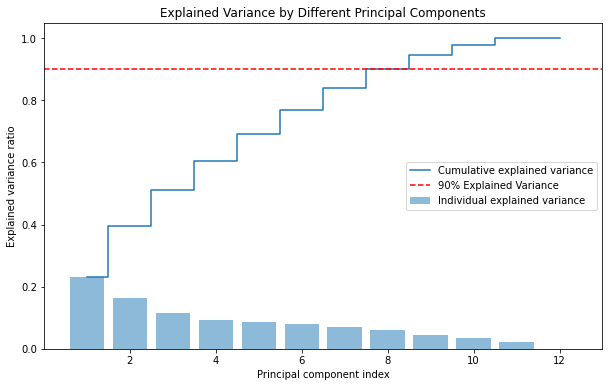

Original shape of the data:  (100, 12)
New shape of the data:  (100, 9)  to retain 90% of the variance.


In [4]:
pca = PCA()
pca.fit(phase1_data_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_explained_variance = explained_variance.cumsum()

# Plotting the explained variance and cumulative explained variance in a table with the principal components as the index
explained_variance_df = pd.DataFrame(explained_variance, index=['PC{}'.format(i) for i in range(1, len(explained_variance) + 1)], columns=['Explained Variance'])
explained_variance_df['Cumulative Explained Variance'] = cumulative_explained_variance
print(explained_variance_df)

# Plotting the explained variances and cumulative explained variances for different principal components 
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.5, align='center', label='Individual explained variance')
plt.step(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, where='mid', label='Cumulative explained variance')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Explained Variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.legend(loc='best')
plt.title('Explained Variance by Different Principal Components')
plt.show()

# Save the reduced PCA data to a new dataframe
print('Original shape of the data: ', phase1_data_scaled.shape)
pca = PCA(n_components=0.9)
phase1_data_pca = pca.fit_transform(phase1_data_scaled)
phase1_data_pca = pd.DataFrame(phase1_data_pca)
print('New shape of the data: ', phase1_data_pca.shape, ' to retain 90% of the variance.')

### 1.4 Anomaly Detector


In [5]:
phase1_data_past_ad = phase1_data_pca.copy()

# Isolation Forest
from sklearn.ensemble import IsolationForest
isolation_forest = IsolationForest()
isolation_forest.fit(phase1_data_pca)
isolation_forest_prediction = isolation_forest.predict(phase1_data_pca)

# Local Outlier Factor
from sklearn.neighbors import LocalOutlierFactor
local_outlier_factor = LocalOutlierFactor()
local_outlier_factor_prediction = local_outlier_factor.fit_predict(phase1_data_pca)

# Add the predictions to the PCA data
phase1_data_past_ad['Isolation Forest'] = isolation_forest_prediction
phase1_data_past_ad['Local Outlier Factor'] = local_outlier_factor_prediction

# Map the predictions to the labels
phase1_data_past_ad['Isolation Forest'] = phase1_data_past_ad['Isolation Forest'].map({1: 'Normal', -1: 'Anomaly'})
phase1_data_past_ad['Local Outlier Factor'] = phase1_data_past_ad['Local Outlier Factor'].map({1: 'Normal', -1: 'Anomaly'})


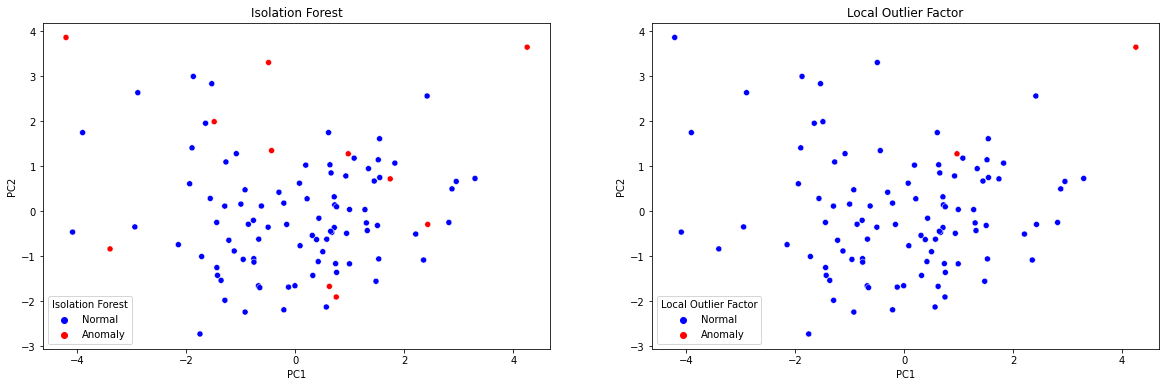

Isolation Forest
Normal     89
Anomaly    11
Name: count, dtype: int64

 Local Outlier Factor
Normal     98
Anomaly     2
Name: count, dtype: int64


In [6]:
# Create one figure with 3 subplots
fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# Visualize the anomalies detected by the Isolation Forest
sns.scatterplot(x=phase1_data_past_ad[0], y=phase1_data_past_ad[1], hue=phase1_data_past_ad['Isolation Forest'], ax=ax[0], palette=['b', 'r'])
ax[0].set_title('Isolation Forest')
ax[0].set_ylabel('PC2')
ax[0].set_xlabel('PC1')

# Visualize the anomalies detected by the Local Outlier Factor
sns.scatterplot(x=phase1_data_past_ad[0], y=phase1_data_past_ad[1], hue=phase1_data_past_ad['Local Outlier Factor'], ax=ax[1], palette=['b', 'r'])
ax[1].set_title('Local Outlier Factor')
ax[1].set_ylabel('PC2')
ax[1].set_xlabel('PC1')

plt.show()

# Print the number of anomalies detected by each model
print(phase1_data_past_ad['Isolation Forest'].value_counts())
print('\n', phase1_data_past_ad['Local Outlier Factor'].value_counts())

<hr>

# Phase 2

In [7]:
phase2_data = pd.read_csv('hcvdat22_Clustering.csv')
phase2_data.head()

,Unnamed: 0,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


### 2.1 Analysis

Given the extensive scope of our current project, we are undertaking a comprehensive analysis of the datasets. This involves employing basic techniques such as 'describe', 'info', and others, as well as generating histograms of individual features to uncover notable insights. These analyses are conducted separately in a distinct file. We will present the findings here as required to inform subsequent steps or decision-making processes.

Summary:

- The new dataset is larger (615 entries vs 100 entries) and includes both genders, offering a more diverse and potentially more representative sample.
- Features like 'ALP', 'ALT', 'AST', 'BIL', and 'GGT' show a wider range of values and greater variability in the new dataset, indicating a more diverse set of measurements.
- The presence of missing values in the new dataset (e.g., 'ALB', 'ALP', 'CHOL', 'PROT') necessitates additional preprocessing steps, unlike the previous dataset which had no missing values.

### 2.2 Preprocessing

In [8]:
# 1. Remove Identifier Column 'Unnamed: 0'
phase2_data = phase2_data.drop(columns = ['Unnamed: 0'], axis=1)

# 2. Encode Categorical Variable 'Sex' to Binary
label_encoder = LabelEncoder()
phase2_data['Sex'] = label_encoder.fit_transform(phase2_data['Sex'])

# 3. Scale the Data using StandardScaler
phase2_data[:] = StandardScaler().fit_transform(phase2_data[:])
phase2_data = pd.DataFrame(phase2_data)
phase2_data.head()

,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,-1.533616,0.794544,-0.540208,-0.606922,-0.815390,-0.383693,-0.198236,-0.574734,-1.889127,0.497070,-0.502286,-0.563913
1,-1.533616,0.794544,-0.540208,0.077522,-0.410658,-0.305057,-0.381375,1.349161,-0.501947,-0.146590,-0.438203,0.825430
2,-1.533616,0.794544,0.914106,0.246711,0.304499,0.538767,-0.269457,0.291926,-0.148525,0.094783,-0.115957,1.344118
3,-1.533616,0.794544,0.273516,-0.626148,0.084451,-0.368571,0.381706,-0.393234,-0.554960,-0.025903,-0.104971,0.677233
4,-1.533616,0.794544,-0.419015,0.223639,0.163040,-0.302033,-0.091404,0.432588,-0.926053,-0.106361,-0.176378,-0.619487


### 2.3 Imputation

##### Imputation Accuracy with MSE

The mean squared error (MSE) in the imputation process quantifies the average squared difference between the original and imputed values, providing a measure of the imputer's accuracy for each column. A lower MSE indicates a closer match to the true data, and thus, a more accurate imputation for that specific feature in the dataset.

In [9]:
# Save the indices of the rows with missing values
imputation_indices = phase2_data[phase2_data.isnull().any(axis=1)].index
imputation_indices

Index([121, 319, 329, 413, 424, 433, 498, 540, 541, 545, 546, 568, 569, 570,
       571, 576, 581, 582, 583, 584, 585, 590, 592, 603, 613, 614],
      dtype='int64')

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.impute import KNNImputer

# Setup for Imputer-Accuracy Comparison
# Dataset for Testing Imputation Accuracy
phase2_data_impute = phase2_data.dropna().copy()
phase2_data_impute_original = phase2_data_impute.copy()

imputers = [
        SimpleImputer(strategy='mean'),
        SimpleImputer(strategy='median'),
        SimpleImputer(strategy='most_frequent'),
        KNNImputer(n_neighbors=2),  # Can test different numbers of neighbors
        IterativeImputer(random_state=0, max_iter=10)
    ]

# Drop random 10% in each column
for col in phase2_data_impute.columns:
    phase2_data_impute.loc[phase2_data_impute.sample(frac=0.1).index, col] = np.nan

In [11]:
impute_result = pd.DataFrame(columns=['column', 'mean', 'median', 'most_frequent', 'KNNImputer', 'IterativeImputer', 'best_imputer'])
for column in phase2_data_impute:
    impute_result.loc[len(impute_result)] = [column, 0, 0, 0, 0, 0, 0]
    for index, imputer in enumerate(imputers):
        imputed_data = pd.DataFrame()
        # Correcting the concatenation here
        new_column_name = column + "_indicator"
        imputed_data[new_column_name] = imputer.fit_transform(phase2_data_impute[column].values.reshape(-1, 1)).ravel()
        impute_result.iloc[len(impute_result)-1, index+1] = mean_squared_error(phase2_data_impute_original[column], imputed_data[new_column_name])
impute_result['best_imputer'] = impute_result.iloc[:, 1:6].idxmin(axis=1)
impute_result

,column,mean,median,most_frequent,KNNImputer,IterativeImputer,best_imputer
0,Age,0.112854,0.111044,0.109614,0.112854,0.112854,most_frequent
1,Sex,0.103941,0.178919,0.178919,0.103941,0.103941,mean
2,ALB,0.104688,0.104139,0.107249,0.104688,0.104688,median
3,ALP,0.365497,0.366745,0.375482,0.365497,0.365497,mean
4,ALT,0.028058,0.027475,0.032349,0.028058,0.028058,median
5,AST,0.033285,0.031321,0.034659,0.033285,0.033285,median
6,BIL,0.069311,0.076888,0.080507,0.069311,0.069311,mean
7,CHE,0.128694,0.128716,0.177033,0.128694,0.128694,mean
8,CHOL,0.116294,0.115480,0.118566,0.116294,0.116294,median
9,CREA,0.009171,0.009716,0.010582,0.009171,0.009171,mean


In [12]:
# Columns with the best imputer
columns_to_impute_with_mean = impute_result[impute_result['best_imputer'] == 'mean']["column"].values
columns_to_impute_with_median = impute_result[impute_result['best_imputer'] == 'median']["column"].values
columns_to_impute_with_most_frequent = impute_result[impute_result['best_imputer'] == 'most_frequent']["column"].values
columns_to_impute_with_knn = impute_result[impute_result['best_imputer'] == 'KNNImputer']["column"].values
columns_to_impute_with_iterative = impute_result[impute_result['best_imputer'] == 'IterativeImputer']["column"].values

In [13]:
columns_to_impute_with_median

array(['ALB', 'ALT', 'AST', 'CHOL'], dtype=object)

In [14]:
# Impute the original data with the best imputer
if len(columns_to_impute_with_mean) > 0:
    mean_imputer = SimpleImputer(strategy='mean')
    phase2_data[columns_to_impute_with_mean] = pd.DataFrame(mean_imputer.fit_transform(phase2_data[columns_to_impute_with_mean]), columns=columns_to_impute_with_mean)

if len(columns_to_impute_with_median) > 0:
    median_imputer = SimpleImputer(strategy='median')
    phase2_data[columns_to_impute_with_median] = pd.DataFrame(median_imputer.fit_transform(phase2_data[columns_to_impute_with_median]), columns=columns_to_impute_with_median)

if len(columns_to_impute_with_most_frequent) > 0:
    most_frequent_imputer = SimpleImputer(strategy='most_frequent')
    phase2_data[columns_to_impute_with_most_frequent] = pd.DataFrame(most_frequent_imputer.fit_transform(phase2_data[columns_to_impute_with_most_frequent]), columns=columns_to_impute_with_most_frequent)

if len(columns_to_impute_with_knn) > 0:
    knn_imputer = KNNImputer(n_neighbors=2)
    phase2_data[columns_to_impute_with_knn] = pd.DataFrame(knn_imputer.fit_transform(phase2_data[columns_to_impute_with_knn]), columns=columns_to_impute_with_knn)

if len(columns_to_impute_with_iterative) > 0:
    iterative_imputer = IterativeImputer(random_state=0, max_iter=10)
    phase2_data[columns_to_impute_with_iterative] = pd.DataFrame(iterative_imputer.fit_transform(phase2_data[columns_to_impute_with_iterative]), columns=columns_to_impute_with_iterative)

# Check if there are any null values left
print(phase2_data.isnull().sum())

# Save the phase2_data to a new csv file
phase2_data.to_csv('hcvdat22_Clustering_Imputed.csv', index=False)



Age     0
Sex     0
ALB     0
ALP     0
ALT     0
AST     0
BIL     0
CHE     0
CHOL    0
CREA    0
GGT     0
PROT    0
dtype: int64


### 2.4 PCA

      Explained Variance  Cumulative Explained Variance
PC1             0.205570                       0.205570
PC2             0.158407                       0.363977
PC3             0.117491                       0.481468
PC4             0.095592                       0.577060
PC5             0.081728                       0.658788
PC6             0.077282                       0.736070
PC7             0.062350                       0.798420
PC8             0.053755                       0.852175
PC9             0.049059                       0.901234
PC10            0.039096                       0.940330
PC11            0.031942                       0.972271
PC12            0.027729                       1.000000


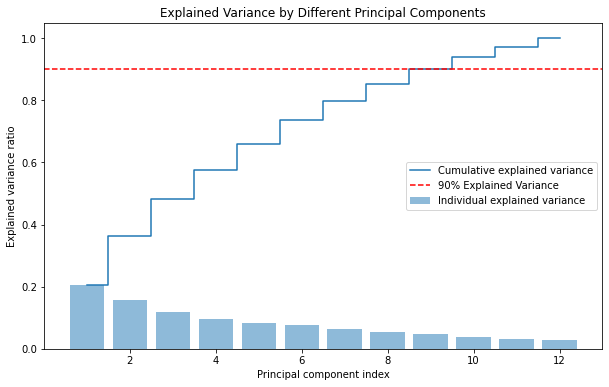

In [15]:
pca_phase2 = PCA()
pca_phase2.fit(phase2_data)

# Explained variance
explained_variance = pca_phase2.explained_variance_ratio_

# Cumulative explained variance
cumulative_explained_variance = explained_variance.cumsum()

# Plotting the explained variance and cumulative explained variance in a table with the principal components as the index
explained_variance_df = pd.DataFrame(explained_variance, index=['PC{}'.format(i) for i in range(1, len(explained_variance) + 1)], columns=['Explained Variance'])
explained_variance_df['Cumulative Explained Variance'] = cumulative_explained_variance
print(explained_variance_df)

# Plotting the explained variances and cumulative explained variances for different principal components 
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.5, align='center', label='Individual explained variance')
plt.step(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, where='mid', label='Cumulative explained variance')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Explained Variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.legend(loc='best')
plt.title('Explained Variance by Different Principal Components')
plt.show()

# Transforming the phase2_data using PCA from Phase 1
phase2_data_pca1 = pca.transform(phase2_data)
phase2_data_pca1 = pd.DataFrame(phase2_data_pca1)

# Save dataframe to csv
phase2_data_pca1.to_csv('hcvdat22_Clustering_PCA.csv', index=False)



##### Comparison PCA Phase 1 - PCA Phase 2

Despite the slightly lower cumulative explained variance in the PCA model trained on 600 data points compared to the one on 100 data points, retraining may not be necessary. This is because the original PCA model already captures the major patterns and variability of the data effectively, and the differences in explained variance are minimal, indicating that the existing model is sufficiently accurate for your project's needs.



### 2.5 Cluster Analysis vs Anomaly Detection

In [16]:
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Dataframe to store the predictions of the different clustering algorithms
cluster_predictions = pd.DataFrame()

# K-Means
kmeans = KMeans()
kmeans.fit(phase2_data_pca1)
kmeans_prediction = kmeans.predict(phase2_data_pca1)

# Hierarchical Clustering
hierarchical_clustering = AgglomerativeClustering()
hierarchical_clustering.fit(phase2_data_pca1)
hierarchical_clustering_prediction = hierarchical_clustering.fit_predict(phase2_data_pca1)

# Add the predictions to the PCA data
cluster_predictions['K-Means'] = kmeans_prediction
cluster_predictions['Hierarchical Clustering'] = hierarchical_clustering_prediction

# Create a dataframe for the Anomaly Detection predictions
anomaly_detection_predictions = pd.DataFrame()

# Isolation Forest Original
# from sklearn.ensemble import IsolationForest
# isolation_forest = IsolationForest()
# isolation_forest.fit(phase2_data_pca1)
# isolation_forest_prediction = isolation_forest.predict(phase2_data_pca1)

# Isolation Forest only with PC1 and PC2 for visualization necessary
from sklearn.ensemble import IsolationForest
isolation_forest = IsolationForest()
isolation_forest.fit(phase2_data_pca1.iloc[:, 0:2])
isolation_forest_prediction = isolation_forest.predict(phase2_data_pca1.iloc[:, 0:2])

# Local Outlier Factor Original
from sklearn.neighbors import LocalOutlierFactor
local_outlier_factor = LocalOutlierFactor()
local_outlier_factor_prediction = local_outlier_factor.fit_predict(phase2_data_pca1)

# Add the predictions to the PCA data
anomaly_detection_predictions['Isolation Forest'] = isolation_forest_prediction
anomaly_detection_predictions['Local Outlier Factor'] = local_outlier_factor_prediction

# Map the predictions to the labels
anomaly_detection_predictions['Isolation Forest'] = anomaly_detection_predictions['Isolation Forest'].map({1: 'Normal', -1: 'Anomaly'})
anomaly_detection_predictions['Local Outlier Factor'] = anomaly_detection_predictions['Local Outlier Factor'].map({1: 'Normal', -1: 'Anomaly'})

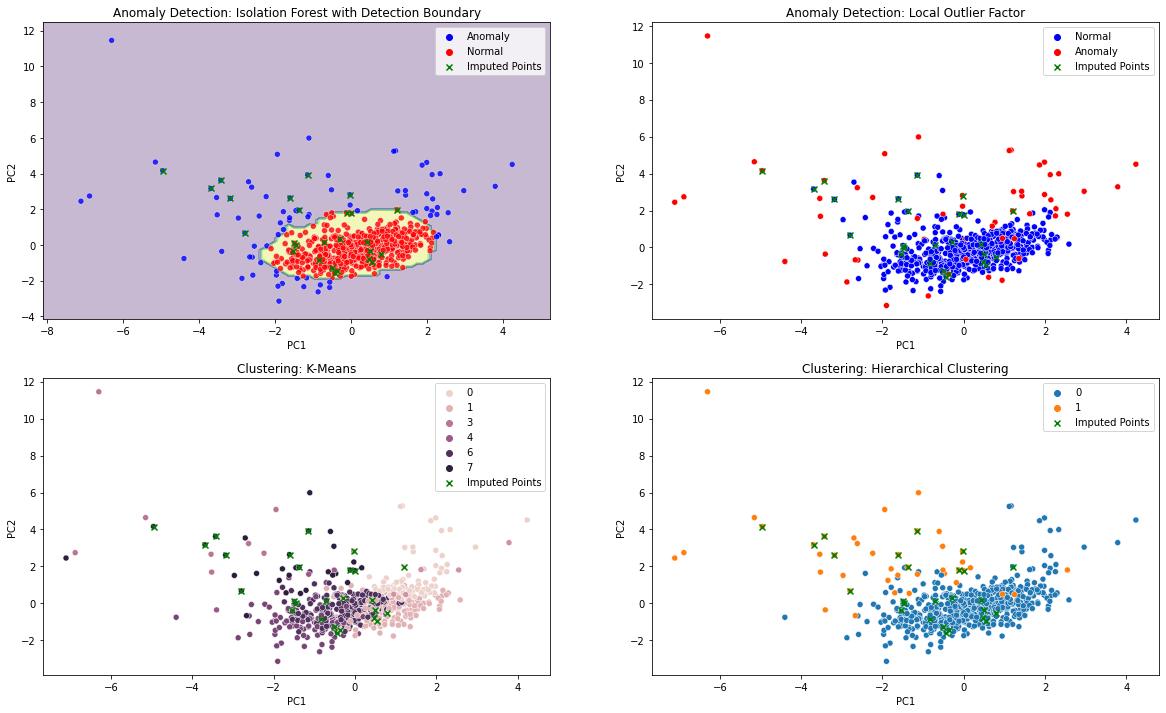

In [17]:
from sklearn.inspection import DecisionBoundaryDisplay

# Create one figure with 6 subplots
fig, ax = plt.subplots(2, 2, figsize=(20, 12))

# Only pc1 and pc2 of the data
#phase2_data_pca1 = phase2_data_pca1.iloc[:, :2]

# Create a decision boundary display for the Isolation Forest
disp = DecisionBoundaryDisplay.from_estimator(
    isolation_forest,
    phase2_data_pca1.iloc[:, :2],
    response_method="predict",
    xlabel="PC1",
    ylabel="PC2",
    ax=ax[0][0],
    alpha=0.3,
)

# Visualize the anomalies detected by the Isolation Forest
sns.scatterplot(x=phase2_data_pca1[0], y=phase2_data_pca1[1], hue=anomaly_detection_predictions['Isolation Forest'], ax=ax[0][0], palette=['b', 'r'], alpha=0.8)
ax[0][0].set_title('Anomaly Detection: Isolation Forest with Detection Boundary')
ax[0][0].set_ylabel('PC2')
ax[0][0].set_xlabel('PC1')

# Visualize the anomalies detected by the Local Outlier Factor
sns.scatterplot(x=phase2_data_pca1[0], y=phase2_data_pca1[1], hue=anomaly_detection_predictions['Local Outlier Factor'], ax=ax[0][1], palette=['b', 'r'])
ax[0][1].set_title('Anomaly Detection: Local Outlier Factor')
ax[0][1].set_ylabel('PC2')
ax[0][1].set_xlabel('PC1')

# Visualize the clusters detected by the K-Means
sns.scatterplot(x=phase2_data_pca1[0], y=phase2_data_pca1[1], hue=cluster_predictions['K-Means'], ax=ax[1][0])
ax[1][0].set_title('Clustering: K-Means')
ax[1][0].set_ylabel('PC2')
ax[1][0].set_xlabel('PC1')

# Visualize the clusters detected by the Hierarchical Clustering
sns.scatterplot(x=phase2_data_pca1[0], y=phase2_data_pca1[1], hue=cluster_predictions['Hierarchical Clustering'], ax=ax[1][1])
ax[1][1].set_title('Clustering: Hierarchical Clustering')
ax[1][1].set_ylabel('PC2')
ax[1][1].set_xlabel('PC1')

# Overlay 'imputation_indices' with a distinct marker on each subplot
for i in range(2):
    for j in range(2):
        ax[i][j].scatter(phase2_data_pca1.iloc[imputation_indices, 0], 
                         phase2_data_pca1.iloc[imputation_indices, 1], 
                         color='green', marker='x', label='Imputed Points')
        ax[i][j].legend(loc='best')


plt.show()


##### Comparison Anomaly Detection vs Cluster Analysis

The Isolation Forest and Local Outlier Factor anomaly detection methods identified outliers scattered throughout the PCA projection, with some agreement on the positioning of these anomalies. The imputed points marked with "X" are distributed across both normal regions and anomalous zones, indicating that imputation was not limited to outliers. In contrast, the K-Means and Hierarchical Clustering algorithms revealed different clustering patterns, with K-Means identifying multiple small clusters and Hierarchical Clustering suggesting a broader, two-cluster division, not directly related to the anomaly detection results.

<hr>

# Phase 3

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.base import BaseEstimator, TransformerMixin

In [19]:
phase3_data = pd.read_csv('hcvdat33_Complete.csv')
phase3_data.head()

,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


### 3.1 Decision Tree Classifier

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin

# Custom transformer to remove a column
class DropColumn(BaseEstimator, TransformerMixin):
    def __init__(self, column):
        self.column = column

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.drop(columns=[self.column])

# List of numerical features
numerical_features = ['Age', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']

# Define the preprocessing steps for the pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(), ['Sex']),
        ('num', SimpleImputer(strategy='median'), numerical_features)
    ])

preprocessor_pipeline = Pipeline(steps=[
    ('remove_id', DropColumn('Unnamed: 0')),
    ('preprocessor', preprocessor)
    ])

# Apply the preprocessing pipeline to the data
X = phase3_data.drop(columns=['Category'])  # Features
y = phase3_data['Category']  # Target

X_preprocessed = preprocessor_pipeline.fit_transform(X)

Decision Tree Classification Accuracy:  0.8703


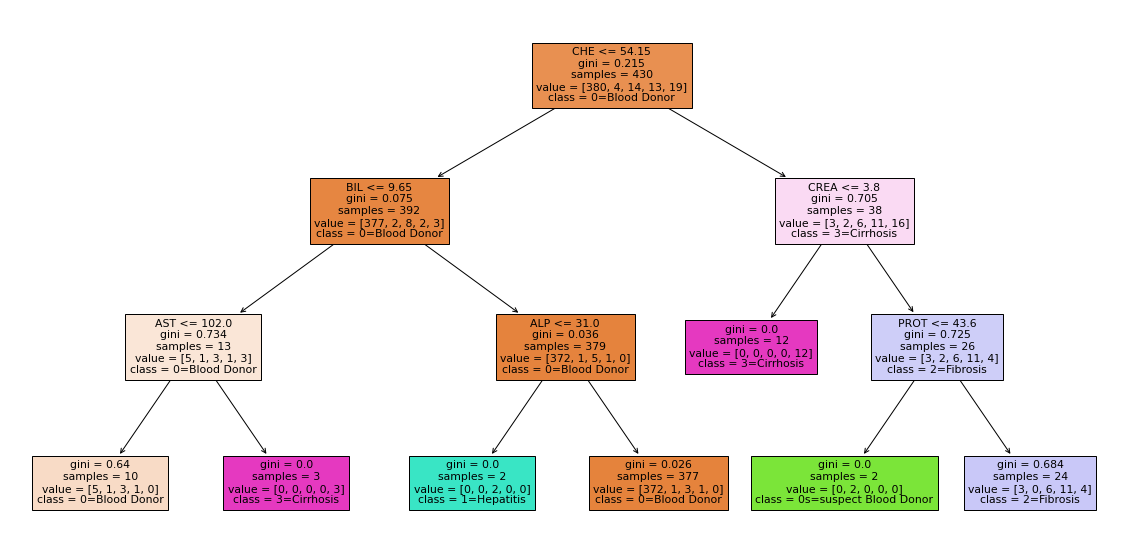

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_preprocessed, y, test_size=0.3, random_state=42)

# Train a decision tree classifier but each inference should put out the class and path taken
dt_classifier = DecisionTreeClassifier(random_state=42, max_depth=3)
dt_classifier.fit(X_train, y_train)

# Predict and evaluate the model
y_pred = dt_classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)


# Print the accuracy
print('Decision Tree Classification Accuracy: ', round(accuracy, 4))

# Visualization of the tree
plt.figure(figsize=(20, 10))
plot_tree(dt_classifier, feature_names=numerical_features + ['Sex_Male', 'Sex_Female'], class_names=dt_classifier.classes_, filled=True)
plt.show()



#### Decision paths

In [22]:
def get_decision_path(decision_tree, feature_names, sample):
    """
    Get the decision path for a given sample from a decision tree classifier.
    
    :param decision_tree: Trained decision tree classifier
    :param feature_names: List of feature names
    :param sample: The sample to analyze
    :return: A string description of the decision path
    """
    # Extract the decision path taken by the sample
    decision_path = decision_tree.decision_path(sample).toarray().squeeze()
    feature = decision_tree.tree_.feature
    threshold = decision_tree.tree_.threshold
    
    # Iterate through the nodes to build the decision path
    node_index = 0
    path_description = []
    for node_indicator in decision_path:
        if node_indicator == 0:
            node_index += 1
            continue  # Skip if the sample did not take the path
        
        # Check if it's not a leaf node
        if feature[node_index] != decision_tree.tree_.children_left[node_index] and feature[node_index] != -2:
            # Check the direction of the sample at the split
            if (sample[0, feature[node_index]] <= threshold[node_index]):
                threshold_sign = "<="
            else:
                threshold_sign = ">"
            
            # Append the description of the path at the current node
            path_description.append(f"{feature_names[feature[node_index]]} {threshold_sign} {threshold[node_index]:.2f}")
        
        node_index += 1
    
    # Join the path descriptions
    return " -> ".join(path_description)


for i, sample in enumerate(X_test):
    # Reshape the sample to match the input shape expected by the decision tree
    sample_reshaped = sample.reshape(1, -1)
    # Get the decision path description for the sample
    path_description = get_decision_path(dt_classifier, numerical_features + ['Sex_Male', 'Sex_Female'], sample_reshaped)
    # Print the path along with the corresponding prediction
    print(f"Sample {i} path: {path_description} -> Predicted class: {y_pred[i]}")

Sample 0 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sample 1 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sample 2 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sample 3 path: CHE > 54.15 -> CREA > 3.80 -> PROT > 43.60 -> Predicted class: 2=Fibrosis
Sample 4 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sample 5 path: CHE > 54.15 -> CREA > 3.80 -> PROT > 43.60 -> Predicted class: 2=Fibrosis
Sample 6 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sample 7 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sample 8 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sample 9 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sample 10 path: CHE <= 54.15 -> BIL > 9.65 -> ALP > 31.00 -> Predicted class: 0=Blood Donor
Sa

### 3.2 Combination with Anomaly Detection and Decision Tree CLF

In [23]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

    
class CustomWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, anomaly_pipeline, decision_tree):
        self.anomaly_pipeline = anomaly_pipeline
        self.decision_tree = decision_tree

    def fit(self, X, y=None):
        # Fit the anomaly pipeline and the decision tree separately
        self.anomaly_pipeline.fit(X, y)
        self.decision_tree.fit(X, y)
        return self

    def predict(self, X):
        # Get predictions from the decision tree
        decision_tree_pred = self.decision_tree.predict(X)
        
        # Get anomaly detection results (assuming the anomaly detector outputs a boolean mask)
        anomaly_pred = self.anomaly_pipeline.predict(X)

        # Logic for prediction:
        # Combine both predictions to compare and evaluate them later
        combined_pred = np.array([decision_tree_pred, anomaly_pred]).T
        
        return combined_pred

# Create the anomaly detection pipeline
anomaly_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('anomaly_detector', IsolationForest())
])

# Create the decision tree pipeline
decision_tree_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('decision_tree', DecisionTreeClassifier(max_depth=3, random_state=42))
])

# Create the custom wrapper with both pipelines
custom_wrapper = CustomWrapper(anomaly_pipeline=anomaly_pipeline, decision_tree=decision_tree_pipeline)

# Show the pipeline
custom_wrapper

CustomWrapper(anomaly_pipeline=Pipeline(steps=[('imputer',
                                                SimpleImputer(strategy='median')),
                                               ('scaler', StandardScaler()),
                                               ('pca', PCA()),
                                               ('anomaly_detector',
                                                IsolationForest())]),
              decision_tree=Pipeline(steps=[('imputer',
                                             SimpleImputer(strategy='median')),
                                            ('decision_tree',
                                             DecisionTreeClassifier(max_depth=3,
                                                                    random_state=42))]))

In [24]:
# Fit the custom wrapper with your data
custom_wrapper.fit(X_train, y_train)

# Predict with the custom wrapper
predictions = custom_wrapper.predict(X_test)

#### Visualization of prediction results

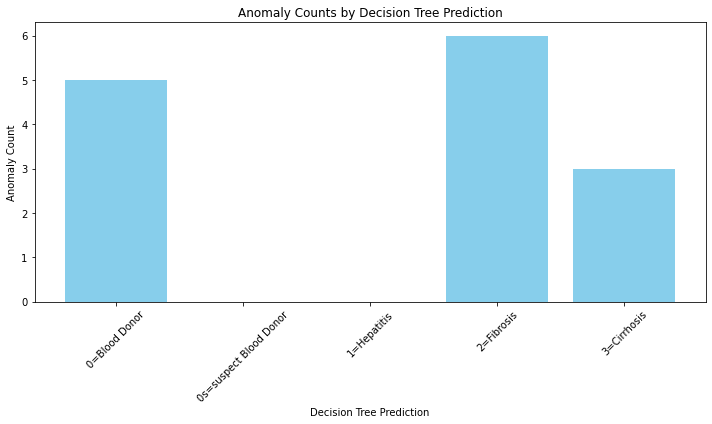

In [25]:
predictions_df = pd.DataFrame(predictions, columns=['Decision Tree Prediction', 'Anomaly Detection Prediction'])

# Convert the Anomaly column to numeric to perform calculations
predictions_df['Anomaly Detection Prediction'] = pd.to_numeric(predictions_df['Anomaly Detection Prediction'])

# Group by 'Class' and count the anomalies
anomaly_counts = predictions_df.groupby('Decision Tree Prediction')['Anomaly Detection Prediction'].apply(lambda x: (x == -1).sum()).reset_index(name='Anomaly Count')


# Now, plot the results
plt.figure(figsize=(10, 6))
plt.bar(anomaly_counts['Decision Tree Prediction'], anomaly_counts['Anomaly Count'], color='skyblue')
plt.xlabel('Decision Tree Prediction')
plt.ylabel('Anomaly Count')
plt.title('Anomaly Counts by Decision Tree Prediction')
plt.xticks(rotation=45)  # Rotate class labels for better readability if needed
plt.tight_layout()  # Adjust layout to fit all labels
plt.show()

<Figure size 720x432 with 0 Axes>

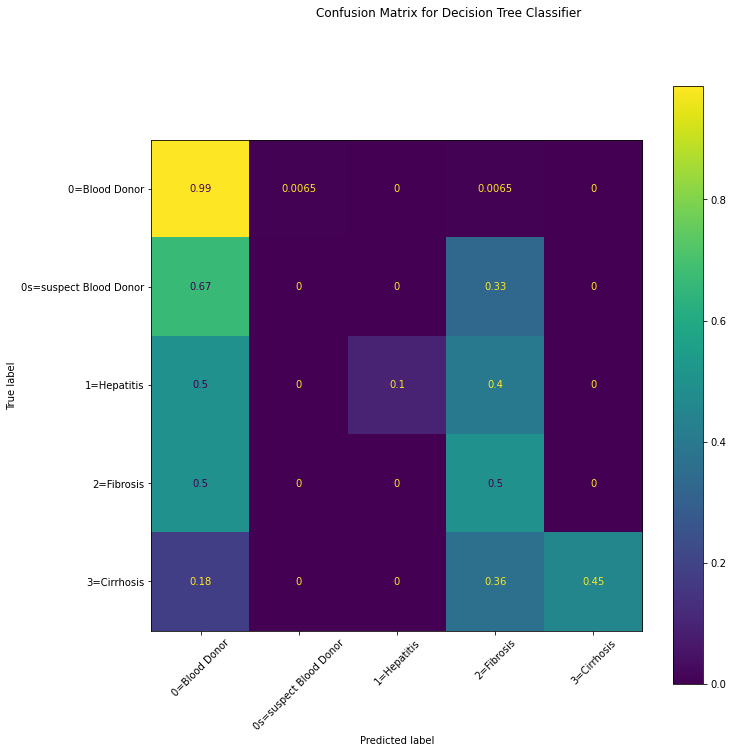

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Assuming y_test are the true labels and y_pred are the predicted labels from your decision tree
plt.figure(figsize=(10, 6))
y_pred = dt_classifier.predict(X_test)
disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=dt_classifier.classes_, normalize='true', xticks_rotation=45)
fig = disp.ax_.get_figure()
fig.suptitle('Confusion Matrix for Decision Tree Classifier')
fig.set_size_inches(11, 11)


### Testing anomaly detection with self-generated anomalies

In [27]:
# Take 3 samples with Category 3=Cirrhosis and 3 samples with 2=Fibrosis nad format them for the custom wrapper
cirrhosis_samples = X_test[y_test == '3=Cirrhosis'][:4]
fibrosis_samples = X_test[y_test == '2=Fibrosis'][:4]

cirrhosis_predictions = custom_wrapper.predict(cirrhosis_samples)
fibrosis_predictions = custom_wrapper.predict(fibrosis_samples)

# Print the predictions
print('Cirrhosis predictions:')
print(cirrhosis_predictions)
print('\nFibrosis predictions:')
print(fibrosis_predictions)

Cirrhosis predictions:
[['2=Fibrosis' -1]
 ['2=Fibrosis' -1]
 ['3=Cirrhosis' -1]
 ['3=Cirrhosis' -1]]

Fibrosis predictions:
[['2=Fibrosis' -1]
 ['2=Fibrosis' 1]
 ['0=Blood Donor' -1]
 ['0=Blood Donor' 1]]


# Summary


Despite the decision tree's high accuracy, it exhibits a less robust detection rate for critical categories such as Hepatitis, Fibrosis, and Cirrhosis. However, the integration of anomaly detection enhances the model's performance, ensuring comprehensive surveillance over these important classes. Additionally, the capability to print decision paths facilitates a deeper understanding of the model's reasoning, enriching interpretability and trust in its judgments.
